# 2D Harmonic Lattice with Free Boundaries

In [3]:
# imports
import numpy as np
%matplotlib widget
import matplotlib.pyplot as plt
import Spring_Mass_Lattice_2D as HL
from scipy.integrate import solve_ivp

In [4]:
# Macros

i = 5 # Number of rows
j = 5 # Number of columns
m = 1 # Mass
k = 1 # Spring Constant
a = 1 # Spring's Natural Length
N = i*j

print(f"Number of rows    : {i}")
print(f"Number of columns : {j}")
print(f"Mass              : {m}")
print(f"Spring constant   : {k}")
print(f"Total particles   : {N}")

Number of rows    : 5
Number of columns : 5
Mass              : 1
Spring constant   : 1
Total particles   : 25


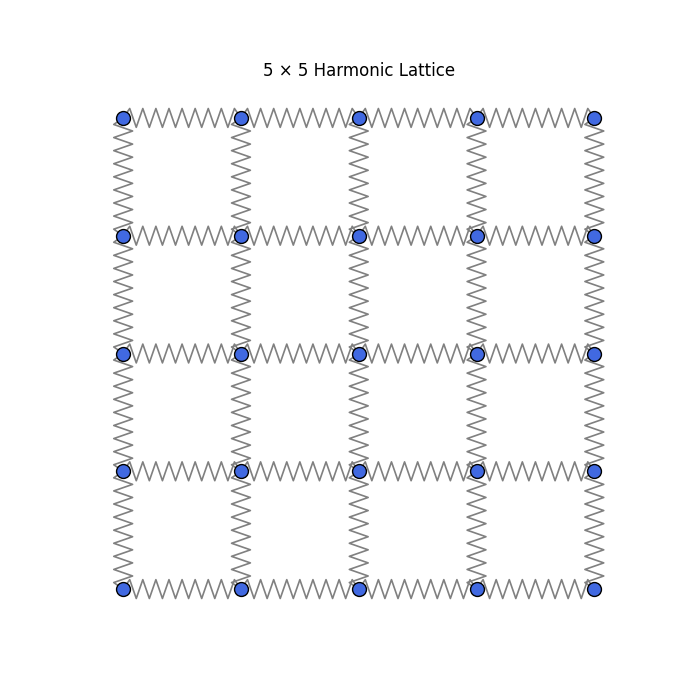

In [5]:
HL.draw_lattice(i, j, boundary="free")

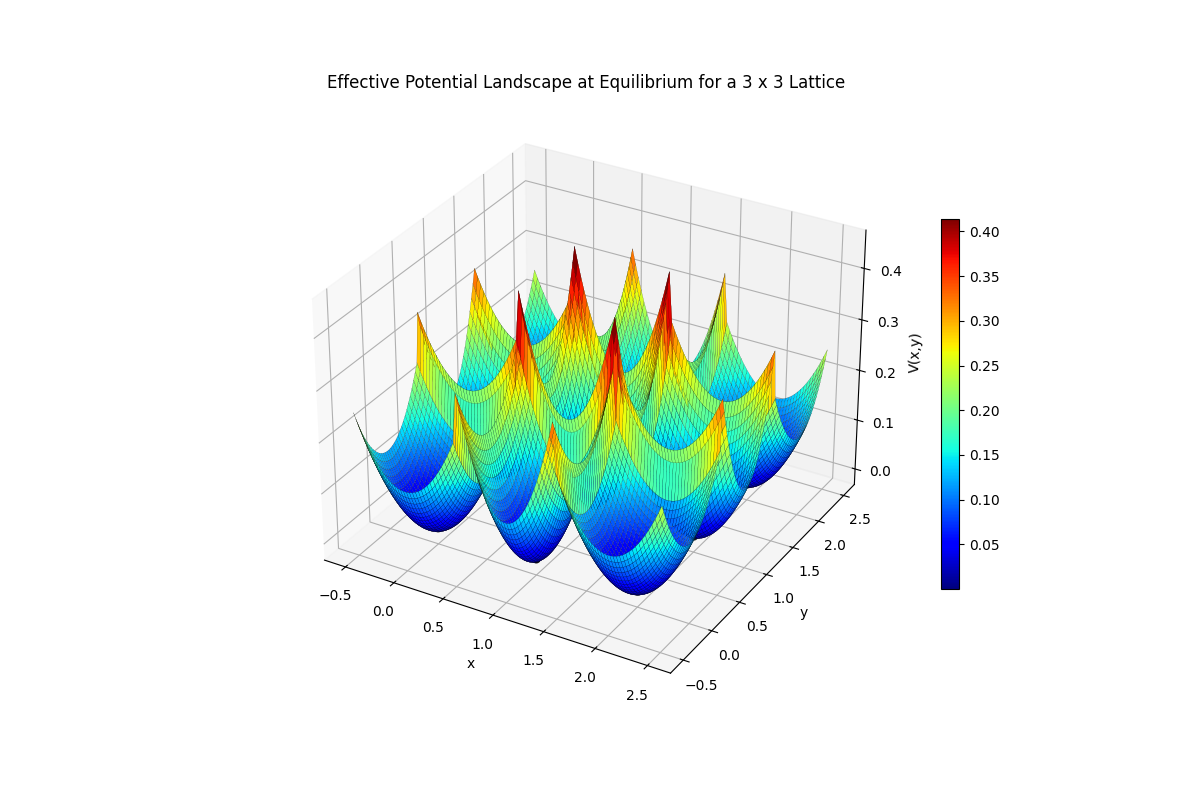

In [6]:
HL.plot_eff_potential_field(k)

## Lagrangian

The simplest model we can come up with is:<br>

$$\mathcal{L} = \sum\limits_{i,j}[\frac{m}{2} (\dot{x}^2_{ij} + \dot{y}^2_{ij}) - \frac{k}{2} (x_{i+1,j} - x_{ij})^2 - \frac{k}{2} (y_{i,j+1} - y_{ij})^2]$$

where $i,j$ denotes the row and column indices respectively, $N, m, k$ denotes the number of masses, their mass and the spring constant.

<!-- ### Other Notations

$\mathbf{u}(x,y)$ : Intial Displacements of the Lattice -->

For this case the Lagrangian can decoupled, giving the Euler-Lagrange Equations:<br>

$$
\begin{aligned}
\frac{d}{dt}\frac{\partial\mathcal{L}}{\partial\dot{x}_{ij}}-\frac{\partial\mathcal{L}}{\partial x_{ij}} &= 0 \\[10pt]
\frac{d}{dt}\frac{\partial\mathcal{L}}{\partial\dot{y}_{ij}}-\frac{\partial\mathcal{L}}{\partial y_{ij}} &= 0
\end{aligned}
$$

And the equations of motion in the $x$-direction are:<br>

For $i,j \neq \partial S$, 
$$
m\ddot{x}_{ij} = k(x_{i+1,j} + x_{i-1,j} - 2x_{ij})
$$

For $i,j = \partial S$, 

$$
\begin{aligned}
m\ddot{x}_{1j} &= k(x_{2,j} - x_{ij}) \\[10pt]
m\ddot{x}_{nj} &= k(x_{n-1,j} - x_{nj})
\end{aligned}
$$

Notice this model can only describe longitudinal restoring forces, but not transverse restoring forces.

# 2D Geometrically Nonlinear 2D Mass-spring Lattice
### 2 Particle Model

In order to better model this system, we have to include the spring's natural length. 

**Consider two particles connected by a spring:**

Positions of the two particles: $\mathbf{r}_1 = (x_1,y_1), \mathbf{r}_2 = (x_2,y_2)$

Seperation between two particles: $l = \sqrt{(x_2 - x_1)^2 + (y_2 - y_1)^2}$

Potential Energy: $U = \frac{k}{2}(l-a)^2$, where $a$ is the natural length of the spring.



Equation of motion for particle 1 in the $x$-direction:

$$
\begin{align}
m\ddot{x_1} &= -\frac{\partial U}{\partial x_1} \\
            &= -k(l-a)\frac{\partial l}{\partial x_1}\\
            &= k(l-a)\left(\frac{x_2-x_1}{l}\right)\\
            &= k\left(1-\frac{a}{l}\right)(x_2-x_1)
\end{align}
$$

Similarly,

$$
m\ddot{y_1} = k\left(1-\frac{a}{l}\right)(y_2-y_1)
$$

In vector form:

$$
\begin{align}
m\ddot{\mathbf{r}}_1 &= k\left(1-\frac{a}{l}\right)(\mathbf{r_2}-\mathbf{r_1}) \\
                   &= k\left(1-\frac{a}{\lvert{\mathbf{r}_2-\mathbf{r}_1}\rvert}\right)(\mathbf{r}_2-\mathbf{r}_1)
\end{align}
$$

### Generalizing to 2D Lattice

For a 2D Lattice with $i$ rows and $j$ columns, 

The position vector of each site is given by:
$$
\mathbf{r}_{ij} =
\begin{bmatrix}
ia + x_{ij} \\
ja + y_{ij}
\end{bmatrix}
$$

The equation of motion is given by:
$$
m\ddot{\mathbf{r}}_{ij} = k\sum\limits_{(p,q) \in \mathcal{N}_{ij}} \left(1 - \frac{a}{\lvert \mathbf{r}_{pq} - \mathbf{r}_{ij}\rvert}\right)(\mathbf{r}_{pq} - \mathbf{r}_{ij})
$$

where $\mathcal{N}_{ij} = \{(i+1.j),(i-1.j),(i.j+1),(i.j-1)\}$ are site $ij$'s immediate neighbours.

Now the system becomes nonlinear:
$$
m\ddot{\mathbf{u}} = \mathbf{F}(\mathbf{u})
$$

### Constructing Position Matrix

In [7]:
X, Y = np.meshgrid(np.arange(i)*a, np.arange(j)*a, indexing="ij")
R = np.stack([X,Y], axis=-1, dtype = float) # R[i,j,x/y]

### Constructing Force Matrix

In [8]:
def spring_force(dr,k,a):
    length = np.linalg.norm(dr, axis=-1, keepdims=True)
    return k * (1 - a/length) * dr

def force_matrix(R,k,a):
    F = np.zeros_like(R, dtype=float)

    # x component
    dr_x = R[1:,:,:] - R[:-1,:,:]
    Fx = spring_force(dr_x,k,a)

    # Adding neighbouring forces
    F[:-1,:,:] += Fx
    F[1:,:,:] -= Fx

     # y component
    dr_y = R[:,1:,:] - R[:,:-1,:]
    Fy = spring_force(dr_y,k,a)
    
    # Adding neighbouring forces
    F[:,:-1,:] += Fy
    F[:,1:,:] -= Fy

    return F

### Sanity Checks

In [9]:
# At equilibrium
assert np.allclose(force_matrix(R, k, a), 0)

# Sum of all forces (Internal Forces) must be zero
R_test = R + np.random.normal(0, 0.1, R.shape)
F = force_matrix(R_test, k, a)
assert np.allclose(F.sum(axis=(0, 1)), 0)

### Solving the coupled system

The equations of motion satisfies:
$$
m\ddot{\mathbf{R}} = \mathbf{F}(\mathbf{R})
$$

Hence we define the velocity matrix $\dot{\mathbf{R}} = \mathbf{V}$.
$$
\frac{d}{dt}\begin{bmatrix} \mathbf{R} \\ \mathbf{V}\end{bmatrix} = \begin{bmatrix} V \\ \frac{1}{m}\mathbf{F}(\mathbf{R})\end{bmatrix}
$$

In [10]:
def equations_of_motion(t, state, i, j, m, k, a):
    R, V = state.reshape(2,i,j,2)
    F = force_matrix(R,k,a)/m
    return np.stack([V,F]).ravel()

In [11]:
R0 = R.copy()
V0 = np.zeros_like(R0)

# Initial Conditions or Perturbations
R0[np.floor(i // 2), :, 1] += 0.5 # Pull the middle column upwards

initial_state = np.stack([R0,V0]).ravel()

sol = solve_ivp(
    equations_of_motion,
    t_span=(0,20),
    y0=initial_state,
    t_eval=np.linspace(0,20,500),
    args=(i,j,m,k,a),
    rtol=1e-9,
    atol=1e-11
)

states = sol.y.T.reshape(-1,2,i,j,2) # states[t,p/v,i,j,x/y]

positions = states[:,0] # positions[t,i,j,x/y]
velocities = states[:,1] # velocities[t,i,j,x/y]

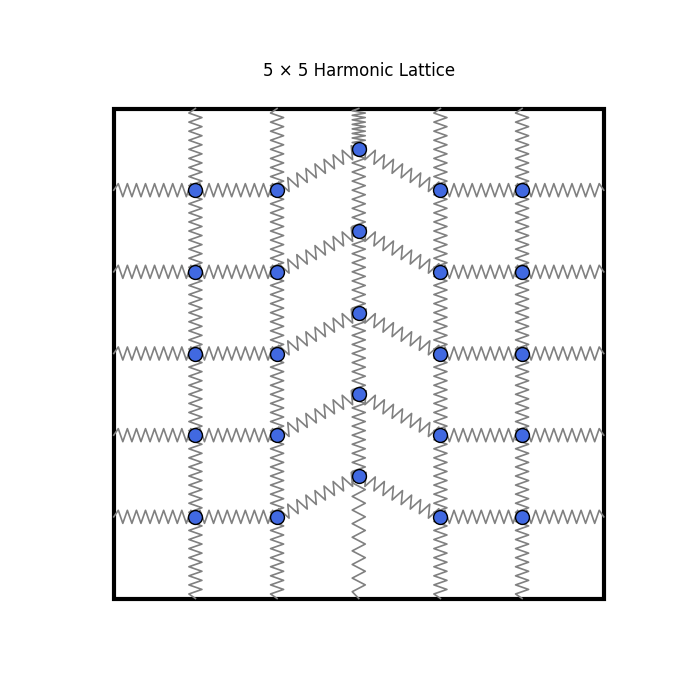

In [12]:
ux = R0[:, :, 0] - np.arange(i)[:, None] * a
uy = R0[:, :, 1] - np.arange(j)[None, :] * a

HL.draw_lattice(i, j, a, ux=ux, uy=uy)

In [13]:
HL.draw_solution(sol, positions, a)